# KG Water Intelligence — Day 5: Exploratory data analysis

**Goal:** understand how weather relates to vegetation (NDVI) in Sokuluk District, using the Day 4 dataset.

**Rule for today:** this is *exploratory* analysis. Nothing here proves water stress, and where the data is too thin to say anything, the notebook says so instead of forcing a pattern.

Data: `data/processed/sokuluk_grid_daily.csv.gz` (one row per day × ERA5-Land grid cell, 30 cells with farmland), the Day 3 district NDVI series and the 10 m NDVI map.

In [1]:
import numpy as np, pandas as pd, rasterio, warnings
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy.stats import spearmanr
warnings.filterwarnings("ignore"); pd.set_option("display.width", 140)
FIG = "../reports/figures/"
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
TEMP, RAIN, NDVI, SPELL = "#eb6834", "#2a78d6", "#2e8b57", "#d9d8d2"
def style(ax, ygrid=True):
    ax.set_facecolor(SURF); [ax.spines[s].set_visible(False) for s in ("top", "right", "left")]
    ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=INK2, length=0, labelsize=10)
    if ygrid: ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
d = pd.read_csv("../data/processed/sokuluk_grid_daily.csv.gz", parse_dates=["date"])
ts = pd.read_csv("../data/processed/sokuluk_ndvi_daily.csv", parse_dates=["date"]).set_index("date")
sp = pd.read_csv("../reports/dry_spells.csv", parse_dates=["start", "end"])
d.head(3)

,date,cell_id,latitude,longitude,cropland_km2,temperature_2m_c,temperature_2m_min_c,temperature_2m_max_c,precipitation_mm,soil_moisture_l1_m3m3,soil_moisture_l2_m3m3,ndvi,ndvi_valid_frac,ndvi_n_pixels,ndvi_n_scenes
0,2018-01-02,9,43.2,74.1,3.64,0.95,-1.31,5.90,0.0,0.3076,0.2954,NaN,NaN,NaN,NaN
1,2018-01-02,10,43.2,74.2,54.03,0.86,-1.37,5.72,0.0,0.3056,0.2931,NaN,NaN,NaN,NaN
2,2018-01-02,11,43.2,74.3,55.21,0.66,-1.61,5.54,0.0,0.3037,0.2904,NaN,NaN,NaN,NaN


## 1. Inspect the dataset

In [2]:
print(f"records: {len(d):,}   columns: {d.shape[1]}")
print(f"date range: {d.date.min().date()} to {d.date.max().date()}  ({d.date.nunique():,} days)   cells: {d.cell_id.nunique()}")
print(f"duplicate (date, cell) rows: {d.duplicated(['date','cell_id']).sum()}")
info = pd.DataFrame({"dtype": d.dtypes.astype(str), "missing": d.isna().sum(), "missing_%": (d.isna().mean() * 100).round(1)})
info

records: 76,680   columns: 15
date range: 2018-01-02 to 2024-12-31  (2,556 days)   cells: 30
duplicate (date, cell) rows: 0


,dtype,missing,missing_%
date,datetime64[ns],0,0.0
cell_id,int64,0,0.0
latitude,float64,0,0.0
longitude,float64,0,0.0
cropland_km2,float64,0,0.0
temperature_2m_c,float64,0,0.0
temperature_2m_min_c,float64,0,0.0
temperature_2m_max_c,float64,0,0.0
precipitation_mm,float64,0,0.0
soil_moisture_l1_m3m3,float64,0,0.0


In [3]:
w0 = d[d.date >= "2023-04-01"]
print(f"NDVI present on {d.ndvi.notna().sum():,} of {len(d):,} rows ({d.ndvi.notna().mean()*100:.1f} %)")
print(f"... but inside the Sentinel-2 window (Apr 2023 - Dec 2024): {w0.ndvi.notna().sum():,} of {len(w0):,} rows ({w0.ndvi.notna().mean()*100:.1f} %)")
print("NDVI rows per year:", d[d.ndvi.notna()].groupby(d.date.dt.year).size().to_dict())
d[["temperature_2m_c", "temperature_2m_min_c", "temperature_2m_max_c", "precipitation_mm", "soil_moisture_l1_m3m3", "soil_moisture_l2_m3m3", "ndvi"]].describe().round(2).T

NDVI present on 2,087 of 76,680 rows (2.7 %)
... but inside the Sentinel-2 window (Apr 2023 - Dec 2024): 2,087 of 19,230 rows (10.9 %)
NDVI rows per year: {2023: 1068, 2024: 1019}


,count,mean,std,min,25%,50%,75%,max
temperature_2m_c,76680.0,8.42,11.53,-28.60,-0.46,8.39,17.85,34.72
temperature_2m_min_c,76680.0,3.01,10.56,-31.34,-4.60,3.19,11.68,27.68
temperature_2m_max_c,76680.0,14.17,12.31,-27.35,4.91,14.23,24.05,42.10
precipitation_mm,76680.0,2.26,4.29,0.00,0.00,0.20,2.52,52.72
soil_moisture_l1_m3m3,76680.0,0.33,0.09,0.12,0.27,0.35,0.39,0.51
soil_moisture_l2_m3m3,76680.0,0.32,0.09,0.14,0.27,0.35,0.39,0.50
ndvi,2087.0,0.37,0.14,0.05,0.27,0.36,0.47,0.87


**Reading the table:** weather is complete (no missing values, physical ranges). NDVI exists only from April 2023 and only on days with a clear satellite pass, so most of the dataset has no NDVI. Everything about NDVI below rests on about two growing seasons.

## 2. Visualizations

In [4]:
# cropland-weighted district series from the grid dataset
wt = lambda g, c: np.average(g[c], weights=g.cropland_km2)
dist = d.groupby("date").apply(lambda g: pd.Series({"t": wt(g, "temperature_2m_c"), "tmin": wt(g, "temperature_2m_min_c"), "tmax": wt(g, "temperature_2m_max_c"), "rain": wt(g, "precipitation_mm"), "sm2": wt(g, "soil_moisture_l2_m3m3")}))
dist.describe().round(2)

,t,tmin,tmax,rain,sm2
count,2556.00,2556.00,2556.00,2556.00,2556.00
mean,11.12,5.32,17.38,1.80,0.30
std,10.63,9.68,11.09,3.64,0.08
min,-20.51,-25.55,-15.36,0.00,0.19
25%,1.82,-2.73,8.04,0.01,0.22
50%,11.69,5.76,18.28,0.24,0.31
75%,20.56,13.79,26.86,1.53,0.37
max,30.83,22.99,38.46,40.59,0.44


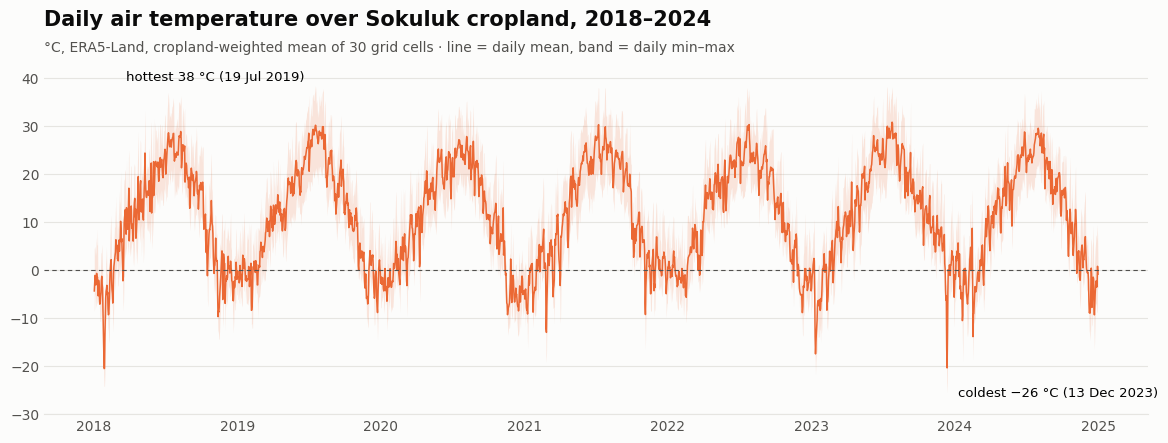

In [5]:
# Figure 1 - daily temperature over time
fig, ax = plt.subplots(figsize=(12, 4.8)); fig.subplots_adjust(left=.055, right=.975, top=.84, bottom=.12); fig.set_facecolor(SURF)
ax.fill_between(dist.index, dist.tmin, dist.tmax, color=TEMP, alpha=.16, lw=0); ax.plot(dist.index, dist.t, color=TEMP, lw=1.1); ax.axhline(0, color=INK2, lw=.8, ls=(0, (4, 3)))
style(ax); ax.set_ylim(-30, 42); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
hot, cold = dist.tmax.idxmax(), dist.tmin.idxmin()
ax.annotate(f"hottest {dist.tmax.max():.0f} °C ({hot:%d %b %Y})", (hot, dist.tmax.max()), xytext=(-8, 4), textcoords="offset points", ha="right", fontsize=9.5)
ax.annotate(f"coldest {dist.tmin.min():.0f} °C ({cold:%d %b %Y})".replace("-", "−"), (cold, dist.tmin.min()), xytext=(8, 0), textcoords="offset points", fontsize=9.5, va="center")
fig.text(.055, .93, "Daily air temperature over Sokuluk cropland, 2018–2024", fontsize=15, fontweight="bold", color=INK)
fig.text(.055, .875, "°C, ERA5-Land, cropland-weighted mean of 30 grid cells · line = daily mean, band = daily min–max", fontsize=10, color=INK2)
fig.savefig(FIG + "eda_temperature.png", dpi=170); plt.show()

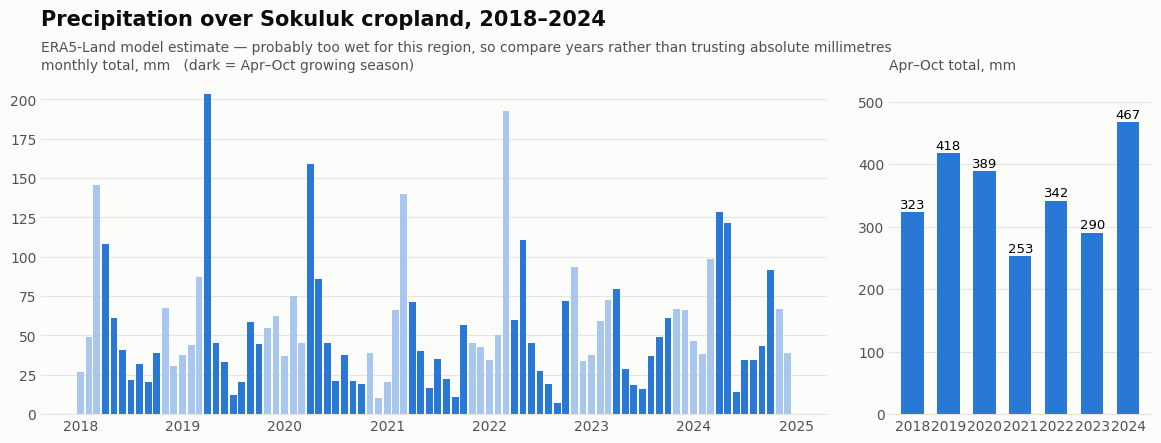

{2018: 323.0, 2019: 418.0, 2020: 389.0, 2021: 253.0, 2022: 342.0, 2023: 290.0, 2024: 467.0}


In [6]:
# Figure 2 - precipitation over time (monthly totals) + Apr-Oct total per year
mon = dist.rain.resample("MS").sum(); yr = dist[dist.index.month.isin(range(4, 11))].rain.groupby(dist[dist.index.month.isin(range(4, 11))].index.year).sum()
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [3, 1]}); fig.subplots_adjust(left=.055, right=.98, top=.82, bottom=.12, wspace=.12); fig.set_facecolor(SURF)
a.bar(mon.index, mon.values, width=24, color=[RAIN if m in range(4, 11) else "#a9c7ee" for m in mon.index.month]); style(a); a.xaxis.set_major_locator(mdates.YearLocator()); a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
a.set_title("monthly total, mm   (dark = Apr–Oct growing season)", loc="left", fontsize=10, color=INK2)
b.bar(yr.index.astype(str), yr.values, color=RAIN, width=.62); style(b); [b.text(i, v + 6, f"{v:.0f}", ha="center", fontsize=9.5) for i, v in enumerate(yr.values)]; b.set_ylim(0, yr.max() * 1.15); b.set_title("Apr–Oct total, mm", loc="left", fontsize=10, color=INK2)
fig.text(.055, .93, "Precipitation over Sokuluk cropland, 2018–2024", fontsize=15, fontweight="bold", color=INK)
fig.text(.055, .875, "ERA5-Land model estimate — probably too wet for this region, so compare years rather than trusting absolute millimetres", fontsize=10, color=INK2)
fig.savefig(FIG + "eda_precipitation.png", dpi=170); plt.show(); print(yr.round(0).to_dict())

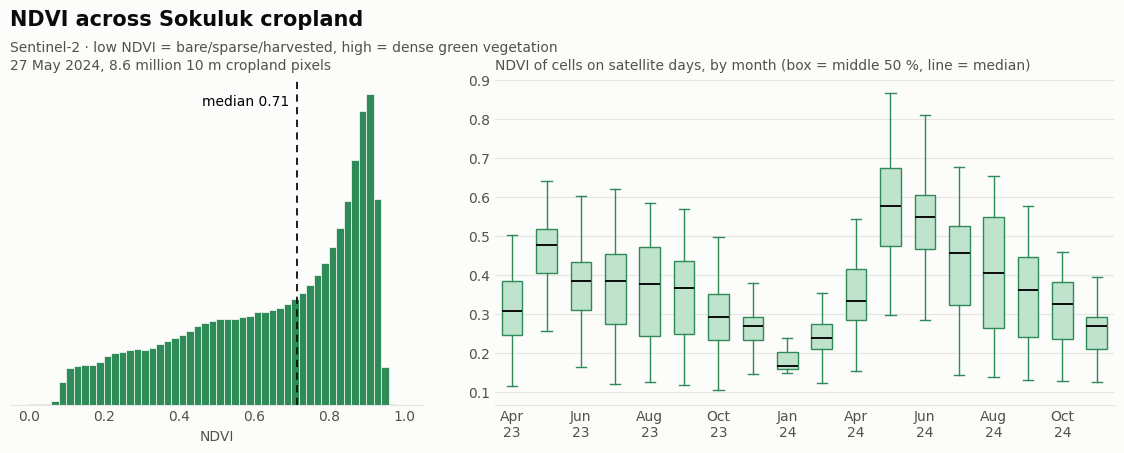

10 m pixels: mean 0.65, 10th-90th percentile 0.28-0.91


In [7]:
# Figure 3 - NDVI distribution across cropland: 10 m pixels on one clear day + cell-level observations by month
with rasterio.open("../data/processed/sokuluk_ndvi.tif") as s: a_ = s.read(1)
px = a_[a_ != -9999]; o = d[d.ndvi.notna()].copy(); o["ym"] = o.date.dt.to_period("M")
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.5]}); fig.subplots_adjust(left=.06, right=.98, top=.82, bottom=.14, wspace=.14); fig.set_facecolor(SURF)
a.hist(px, bins=np.linspace(0, 1, 51), color=NDVI, edgecolor=SURF, lw=.5); style(a); a.set_yticks([]); a.axvline(np.median(px), color=INK, lw=1.3, ls=(0, (4, 3))); a.text(np.median(px) - .02, a.get_ylim()[1] * .95, f"median {np.median(px):.2f}", ha="right", va="top", fontsize=10)
a.set_title(f"27 May 2024, {len(px)/1e6:.1f} million 10 m cropland pixels", loc="left", fontsize=10, color=INK2); a.set_xlabel("NDVI", color=INK2)
months = sorted(o.ym.unique()); b.boxplot([o[o.ym == m].ndvi for m in months], positions=range(len(months)), widths=.6, patch_artist=True, showfliers=False, medianprops=dict(color=INK, lw=1.4),
    boxprops=dict(facecolor="#bfe3cd", edgecolor=NDVI), whiskerprops=dict(color=NDVI), capprops=dict(color=NDVI)); style(b)
b.set_xticks(range(0, len(months), 2)); b.set_xticklabels([months[i].strftime("%b\n%y") for i in range(0, len(months), 2)]); b.set_title("NDVI of cells on satellite days, by month (box = middle 50 %, line = median)", loc="left", fontsize=10, color=INK2)
fig.text(.06, .93, "NDVI across Sokuluk cropland", fontsize=15, fontweight="bold", color=INK); fig.text(.06, .875, "Sentinel-2 · low NDVI = bare/sparse/harvested, high = dense green vegetation", fontsize=10, color=INK2)
fig.savefig(FIG + "eda_ndvi_distribution.png", dpi=170); plt.show()
print(f"10 m pixels: mean {px.mean():.2f}, 10th-90th percentile {np.percentile(px,10):.2f}-{np.percentile(px,90):.2f}")

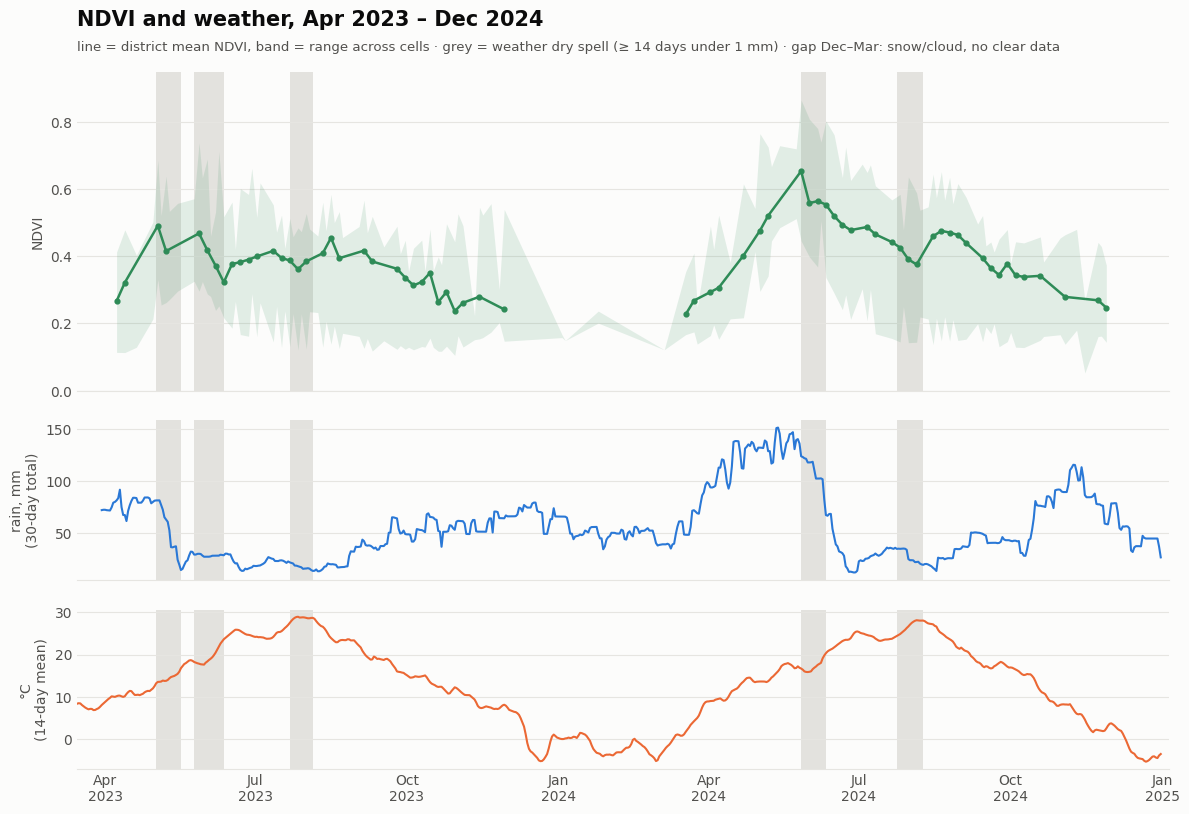

In [8]:
# Figure 4 - NDVI over time with weather underneath (one axis each, shared dates)
tw = dist[dist.index >= "2023-03-01"]; good = ts[ts.valid_frac >= .3]; spread = d[d.ndvi.notna()].groupby("date").ndvi.agg(["min", "max"])
fig, ax = plt.subplots(3, 1, figsize=(12, 8.4), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]}); fig.subplots_adjust(left=.07, right=.98, top=.9, bottom=.07, hspace=.14); fig.set_facecolor(SURF)
seg = (good.index.to_series().diff() > pd.Timedelta(days=60)).cumsum()
ax[0].fill_between(spread.index, spread["min"], spread["max"], color=NDVI, alpha=.13, lw=0)
for _, g_ in good.groupby(seg.values): ax[0].plot(g_.index, g_.ndvi_mean, color=NDVI, lw=1.8)
ax[0].scatter(good.index, good.ndvi_mean, s=12, color=NDVI); ax[0].set_ylim(0, .95); style(ax[0]); ax[0].set_ylabel("NDVI", color=INK2)
for s_, e_ in zip(sp.start, sp.end): [x.axvspan(s_, e_, color=SPELL, alpha=.7, lw=0, zorder=0) for x in ax]
ax[1].plot(tw.index, tw.rain.rolling(30).sum(), color=RAIN, lw=1.5); style(ax[1]); ax[1].set_ylabel("rain, mm\n(30-day total)", color=INK2)
ax[2].plot(tw.index, tw.t.rolling(14).mean(), color=TEMP, lw=1.5); style(ax[2]); ax[2].set_ylabel("°C\n(14-day mean)", color=INK2)
ax[2].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); ax[2].set_xlim(pd.Timestamp("2023-03-15"), pd.Timestamp("2025-01-05"))
fig.text(.07, .955, "NDVI and weather, Apr 2023 – Dec 2024", fontsize=15, fontweight="bold", color=INK)
fig.text(.07, .925, "line = district mean NDVI, band = range across cells · grey = weather dry spell (≥ 14 days under 1 mm) · gap Dec–Mar: snow/cloud, no clear data", fontsize=9.6, color=INK2)
fig.savefig(FIG + "eda_ndvi_timeseries.png", dpi=170); plt.show()

## 3. Relationships between weather and NDVI (exploratory)

Three traps to avoid: (1) **season** — NDVI and temperature both rise in spring, which creates a correlation that is not about water; (2) **place** — cells differ a lot in climate (plain vs foothills), so cell comparisons can reflect land type; (3) **tiny sample** — two growing seasons. So I test the question in three increasingly careful ways.

In [9]:
# prior-weather features for every cell-day
d = d.sort_values(["cell_id", "date"]).reset_index(drop=True); g = d.groupby("cell_id")
d["rain_7"] = g.precipitation_mm.transform(lambda s: s.rolling(7).sum()); d["rain_30"] = g.precipitation_mm.transform(lambda s: s.rolling(30).sum()); d["rain_60"] = g.precipitation_mm.transform(lambda s: s.rolling(60).sum())
d["tmean_14"] = g.temperature_2m_c.transform(lambda s: s.rolling(14).mean()); d["sm2_7"] = g.soil_moisture_l2_m3m3.transform(lambda s: s.rolling(7).mean())
feats = {"rain_7": "rain, prior 7 d", "rain_30": "rain, prior 30 d", "rain_60": "rain, prior 60 d", "tmean_14": "mean temp, prior 14 d", "sm2_7": "soil moisture (7-28 cm), 7 d mean"}
o = d[d.ndvi.notna()].copy()
# (A) pooled: all cells and dates together -- confounded by season
A = pd.Series({lab: spearmanr(o.ndvi, o[f], nan_policy="omit").statistic for f, lab in feats.items()}).round(2)
print("(A) pooled Spearman correlation with NDVI (season-confounded), n =", len(o)); A

(A) pooled Spearman correlation with NDVI (season-confounded), n = 2087


rain, prior 7 d                     -0.03
rain, prior 30 d                     0.06
rain, prior 60 d                     0.16
mean temp, prior 14 d                0.22
soil moisture (7-28 cm), 7 d mean   -0.10
dtype: float64

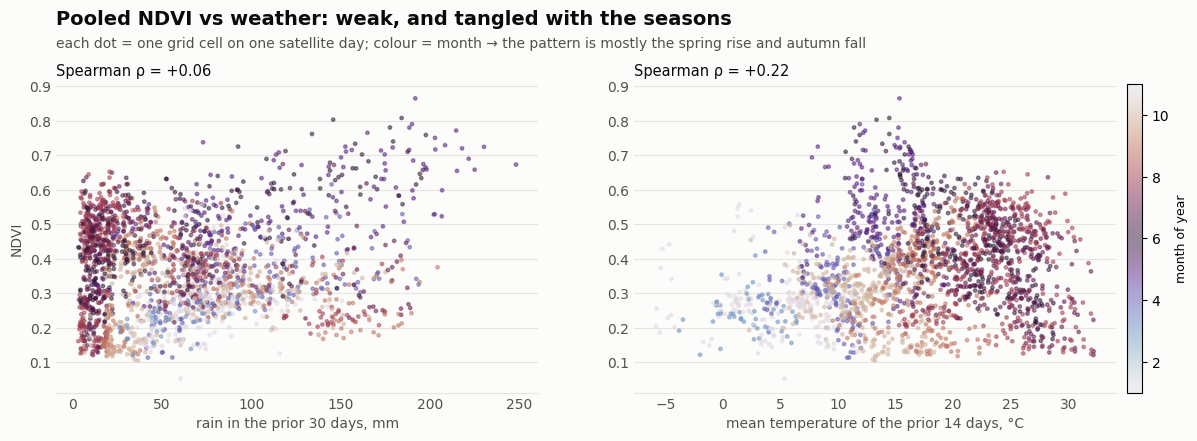

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6)); fig.subplots_adjust(left=.06, right=.97, top=.8, bottom=.13, wspace=.2); fig.set_facecolor(SURF)
cmap = plt.get_cmap("viridis")
for a, f, xl in ((ax[0], "rain_30", "rain in the prior 30 days, mm"), (ax[1], "tmean_14", "mean temperature of the prior 14 days, °C")):
    sc = a.scatter(o[f], o.ndvi, c=o.date.dt.month, cmap="twilight", s=6, alpha=.5); style(a); a.set_xlabel(xl, color=INK2); a.set_ylabel("NDVI" if f == "rain_30" else "", color=INK2)
    a.set_title(f"Spearman ρ = {spearmanr(o.ndvi, o[f], nan_policy='omit').statistic:+.2f}", loc="left", fontsize=10.5, color=INK)
cb = fig.colorbar(sc, ax=ax, pad=.01, fraction=.02); cb.set_label("month of year", fontsize=9)
fig.text(.06, .93, "Pooled NDVI vs weather: weak, and tangled with the seasons", fontsize=14, fontweight="bold", color=INK)
fig.text(.06, .88, "each dot = one grid cell on one satellite day; colour = month → the pattern is mostly the spring rise and autumn fall", fontsize=10, color=INK2)
fig.savefig(FIG + "eda_pooled_scatter.png", dpi=170); plt.show()

In [11]:
# (B) same-date comparison across cells: removes the season (all cells share the date) but keeps the spatial pattern
res = {f: [] for f in feats}
for dt, gg in o.groupby("date"):
    gg = gg.dropna(subset=["ndvi"] + list(feats))
    if len(gg) >= 10:
        for f in feats:
            if gg[f].nunique() > 3: res[f].append(spearmanr(gg.ndvi, gg[f]).statistic)
B = pd.DataFrame({lab: {"dates": len(res[f]), "median ρ": np.median(res[f]), "share of dates ρ>0": np.mean(np.array(res[f]) > 0)} for f, lab in feats.items()}).T.round(2)
print("(B) same-date correlation across cells (one correlation per satellite day, then summarised)"); display(B)
cell = d[d.date >= "2023-04-01"].groupby("cell_id").agg(ndvi=("ndvi", "mean"), temp=("temperature_2m_c", "mean"), lat=("latitude", "first")); cell["rain_yr"] = d[d.date.dt.year == 2024].groupby("cell_id").precipitation_mm.sum()
cell = cell.dropna()
print(f"cells differ a lot: mean temperature {cell.temp.min():.1f} to {cell.temp.max():.1f} °C, 2024 rain {cell.rain_yr.min():.0f} to {cell.rain_yr.max():.0f} mm  -> plain vs foothills")
print(f"cell-average NDVI vs cell-average temperature: rho = {spearmanr(cell.ndvi, cell.temp).statistic:+.2f} (n = {len(cell)} cells)")

(B) same-date correlation across cells (one correlation per satellite day, then summarised)

,dates,median ρ,share of dates ρ>0
"rain, prior 7 d",68.0,0.29,0.81
"rain, prior 30 d",68.0,0.33,0.85
"rain, prior 60 d",68.0,0.37,0.85
"mean temp, prior 14 d",68.0,-0.41,0.01
"soil moisture (7-28 cm), 7 d mean",68.0,0.08,0.62


cells differ a lot: mean temperature 6.8 to 15.0 °C, 2024 rain 480 to 1386 mm  -> plain vs foothills
cell-average NDVI vs cell-average temperature: rho = -0.33 (n = 25 cells)


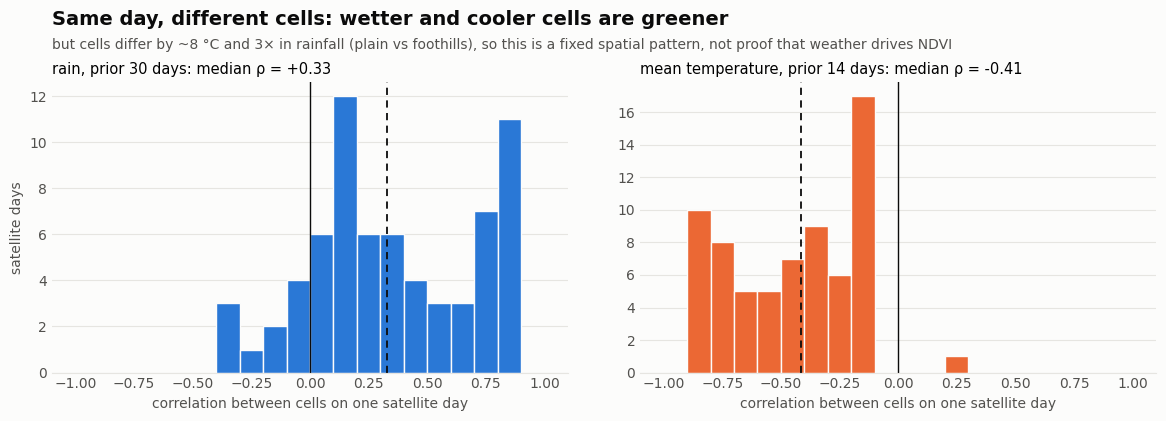

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4)); fig.subplots_adjust(left=.06, right=.98, top=.8, bottom=.14, wspace=.14); fig.set_facecolor(SURF)
for a, f, col, ttl in ((ax[0], "rain_30", RAIN, "rain, prior 30 days"), (ax[1], "tmean_14", TEMP, "mean temperature, prior 14 days")):
    r = np.array(res[f]); a.hist(r, bins=np.linspace(-1, 1, 21), color=col, edgecolor=SURF); style(a); a.axvline(0, color=INK, lw=1); a.axvline(np.median(r), color=INK, lw=1.3, ls=(0, (4, 3)))
    a.set_title(f"{ttl}: median ρ = {np.median(r):+.2f}", loc="left", fontsize=10.5); a.set_xlabel("correlation between cells on one satellite day", color=INK2); a.set_ylabel("satellite days" if f == "rain_30" else "", color=INK2)
fig.text(.06, .93, "Same day, different cells: wetter and cooler cells are greener", fontsize=14, fontweight="bold", color=INK)
fig.text(.06, .875, "but cells differ by ~8 °C and 3× in rainfall (plain vs foothills), so this is a fixed spatial pattern, not proof that weather drives NDVI", fontsize=10, color=INK2)
fig.savefig(FIG + "eda_same_date_cells.png", dpi=170); plt.show()

In [13]:
# (C) year-over-year change inside each cell: removes season AND place (each cell is compared with itself, same calendar month)
d["y"] = d.date.dt.year; d["m"] = d.date.dt.month; ww = d[(d.date >= "2023-04-01") & d.m.between(4, 10)]
cm = ww.groupby(["cell_id", "y", "m"]).agg(ndvi=("ndvi", "mean"), rain=("precipitation_mm", "sum"), temp=("temperature_2m_c", "mean"), nobs=("ndvi", "count")).reset_index()
a3, b4 = cm[cm.y == 2023].set_index(["cell_id", "m"]), cm[cm.y == 2024].set_index(["cell_id", "m"]); j = b4.join(a3, lsuffix="_24", rsuffix="_23", how="inner"); j = j[(j.nobs_24 >= 2) & (j.nobs_23 >= 2)].dropna(subset=["ndvi_24", "ndvi_23"])
j["dN"], j["dR"], j["dT"] = j.ndvi_24 - j.ndvi_23, j.rain_24 - j.rain_23, j.temp_24 - j.temp_23
print(f"(C) {len(j)} cell-months, {j.index.get_level_values(0).nunique()} cells: 2024 minus 2023, same calendar month")
print(f"pooled Spearman: dNDVI vs dRain = {spearmanr(j.dN, j.dR).statistic:+.2f}   dNDVI vs dTemp = {spearmanr(j.dN, j.dT).statistic:+.2f}")
bym = j.groupby(level=1).apply(lambda g: pd.Series({"cells": len(g), "mean dNDVI": g.dN.mean(), "rho(dNDVI,dRain)": spearmanr(g.dN, g.dR).statistic, "rho(dNDVI,dTemp)": spearmanr(g.dN, g.dT).statistic})).round(2); bym.index.name = "month"; bym

(C) 174 cell-months, 25 cells: 2024 minus 2023, same calendar month
pooled Spearman: dNDVI vs dRain = +0.14   dNDVI vs dTemp = -0.05


,cells,mean dNDVI,"rho(dNDVI,dRain)","rho(dNDVI,dTemp)"
month,,,,
4,24.0,0.04,-0.54,-0.39
5,25.0,0.12,0.47,0.72
6,25.0,0.16,-0.76,0.38
7,25.0,0.06,0.53,0.51
8,25.0,0.05,-0.42,-0.20
9,25.0,0.01,0.27,-0.14
10,25.0,0.03,-0.28,0.29


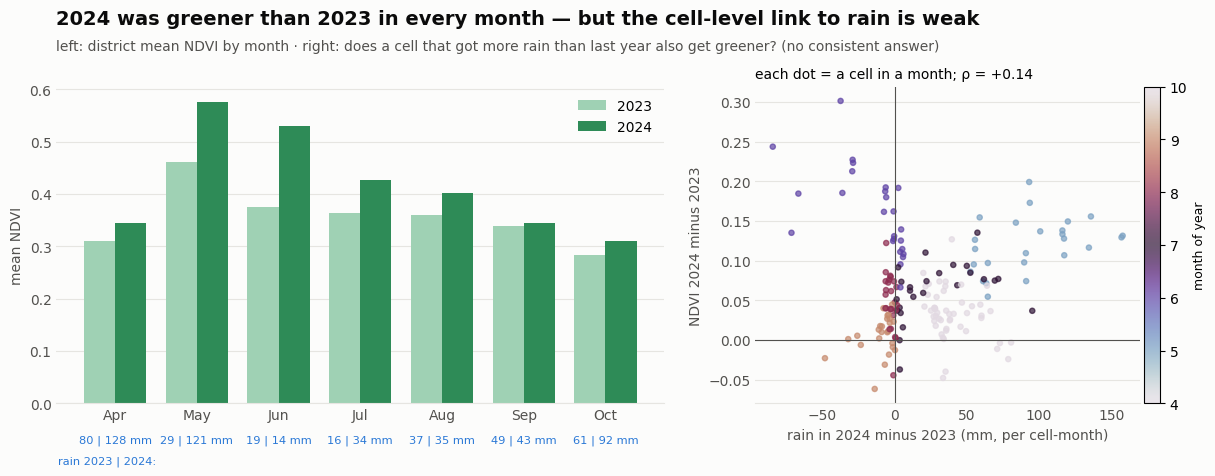

Apr+May rain: 2023 = 108 mm, 2024 = 249 mm;  months where 2024 NDVI > 2023: 7 of 7


In [14]:
# district level: 2023 vs 2024 by month
dd = d[(d.date >= "2023-04-01") & d.m.between(4, 10)]
mon = dd.groupby(["y", "m"]).apply(lambda x: pd.Series({"ndvi": x.ndvi.mean(), "rain": x.groupby("date").apply(lambda z: wt(z, "precipitation_mm")).sum(), "temp": x.groupby("date").apply(lambda z: wt(z, "temperature_2m_c")).mean()})).unstack(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.5, 1]}); fig.subplots_adjust(left=.06, right=.98, top=.8, bottom=.14, wspace=.18); fig.set_facecolor(SURF)
x = np.arange(7); lab = ["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"]
ax[0].bar(x - .19, mon["ndvi"][2023], .38, color="#9fd1b4", label="2023"); ax[0].bar(x + .19, mon["ndvi"][2024], .38, color=NDVI, label="2024"); style(ax[0]); ax[0].set_xticks(x); ax[0].set_xticklabels(lab)
ax[0].legend(frameon=False, loc="upper right"); ax[0].set_ylabel("mean NDVI", color=INK2)
for i in range(7): ax[0].text(i, -.075, f"{mon['rain'][2023].iloc[i]:.0f} | {mon['rain'][2024].iloc[i]:.0f} mm", ha="center", fontsize=8.2, color=RAIN, clip_on=False)
ax[0].text(-.7, -.115, "rain 2023 | 2024:", fontsize=8.2, color=RAIN, clip_on=False)
sc2 = ax[1].scatter(j.dR, j.dN, c=j.index.get_level_values(1), cmap="twilight", s=14, alpha=.7); style(ax[1]); fig.colorbar(sc2, ax=ax[1], pad=.01, fraction=.04).set_label("month of year", fontsize=9); ax[1].axhline(0, color=INK2, lw=.8); ax[1].axvline(0, color=INK2, lw=.8)
ax[1].set_xlabel("rain in 2024 minus 2023 (mm, per cell-month)", color=INK2); ax[1].set_ylabel("NDVI 2024 minus 2023", color=INK2); ax[1].set_title(f"each dot = a cell in a month; ρ = {spearmanr(j.dN, j.dR).statistic:+.2f}", loc="left", fontsize=10)
fig.text(.06, .93, "2024 was greener than 2023 in every month — but the cell-level link to rain is weak", fontsize=14, fontweight="bold", color=INK)
fig.text(.06, .875, "left: district mean NDVI by month · right: does a cell that got more rain than last year also get greener? (no consistent answer)", fontsize=10, color=INK2)
fig.savefig(FIG + "eda_2023_vs_2024.png", dpi=170); plt.show()
spr = mon["rain"].loc[[4, 5]].sum(); print(f"Apr+May rain: 2023 = {spr[2023]:.0f} mm, 2024 = {spr[2024]:.0f} mm;  months where 2024 NDVI > 2023: {(mon['ndvi'][2024] > mon['ndvi'][2023]).sum()} of 7")

In [15]:
# (D) a closer look at the dry spells that fall inside the NDVI window: did NDVI drop during them?
good = ts[ts.valid_frac >= .3]; near = lambda dt, before: (good.loc[dt - pd.Timedelta(days=6):dt].iloc[-1:] if before else good.loc[dt:dt + pd.Timedelta(days=6)].iloc[:1])
rows = []
for r in sp[sp.start >= "2023-04-01"].itertuples():
    b_, a_ = near(r.start, True), near(r.end, False)
    rows.append({"spell": f"{r.start:%d %b %y} – {r.end:%d %b %y}", "days": r.days, "NDVI before": b_.ndvi_mean.iloc[0] if len(b_) else np.nan, "NDVI after": a_.ndvi_mean.iloc[0] if len(a_) else np.nan})
ev = pd.DataFrame(rows); ev["change"] = ev["NDVI after"] - ev["NDVI before"]
chg = []
for s0 in pd.date_range("2023-04-10", "2024-10-31", freq="3D"):
    if 4 <= s0.month <= 10:
        sb, sa = good.loc[s0 - pd.Timedelta(days=6):s0], good.loc[s0 + pd.Timedelta(days=16):s0 + pd.Timedelta(days=22)]
        if len(sb) and len(sa): chg.append(sa.iloc[0].ndvi_mean - sb.iloc[-1].ndvi_mean)
chg = np.array(chg); print(f"normal NDVI change over a 16-day window in Apr–Oct (n = {len(chg)}): median {np.median(chg):+.3f}, middle 80 % between {np.percentile(chg,10):+.3f} and {np.percentile(chg,90):+.3f}")
print(f"{ev['change'].notna().sum()} of {len(ev)} dry spells in the window have a clear NDVI observation before AND after"); ev.round(3)

normal NDVI change over a 16-day window in Apr–Oct (n = 87): median -0.026, middle 80 % between -0.088 and +0.094
3 of 5 dry spells in the window have a clear NDVI observation before AND after


,spell,days,NDVI before,NDVI after,change
0,02 May 23 – 17 May 23,16,NaN,NaN,NaN
1,25 May 23 – 12 Jun 23,19,NaN,0.323,NaN
2,22 Jul 23 – 05 Aug 23,15,0.388,0.409,0.022
3,27 May 24 – 11 Jun 24,16,0.654,0.554,-0.099
4,24 Jul 24 – 09 Aug 24,17,0.442,0.460,0.017


## 4. Findings

### Three observations
1. **2024 was greener than 2023 in every month from April to October** (district NDVI +0.01 to +0.16; biggest in May and June). The year also had much more spring rain (Apr–May about 250 mm vs about 110 mm in the model) and fewer hot days, which fits the idea that moisture matters, but June's gap is not explained by rain and there are only two years.
2. **Raw correlations between weather and NDVI are weak (|ρ| ≤ 0.22) and mostly seasonal.** Comparing cells on the same day, wetter and cooler cells are greener (median ρ about +0.3 for rain, −0.4 for temperature, on 85 % and 99 % of days). But the cells differ by about 8 °C and a factor of three in rain (plain versus foothills), so this is a fixed spatial pattern, not evidence that weather drives NDVI.
3. **Once season and place are both removed, no consistent weather–NDVI relationship is visible.** Comparing each cell with itself (2024 minus 2023, same month) gives ρ = +0.14 for rain and −0.05 for temperature, and the sign flips from month to month. Of the five dry spells in the NDVI window, only three have clear observations before and after, and the NDVI changes across them (+0.02, −0.10, +0.02) fall inside the normal 16-day range (about −0.09 to +0.09).

### Two data limitations
1. **NDVI is short and sparse.** About two growing seasons, 2.7 % of dataset rows, nothing from December to mid-March. With no multi-year baseline, "lower than normal" cannot be measured; only 2023 against 2024 can be compared.
2. **The unit of analysis hides what matters.** Weather cells are about 9 km wide, irrigation, crop type and sowing date are unknown, ERA5 rain looks too high, and NDVI measures greenness (ripening and harvest also lower it), so a weather effect cannot be separated from land type or management.

### One question to investigate next
**Does NDVI fall below its *own seasonal norm* after hot, dry periods once crop phenology is accounted for?** Answering it needs a multi-year NDVI baseline (Sentinel-2 back to 2018) to define "below normal", and ideally a second stress indicator that does not depend on NDVI (e.g. soil-moisture or evaporation deficit). That is the work of Day 6: define a measurable water-stress indicator and check what can serve as a reliable target.

*Exploratory only: nothing in this notebook demonstrates water stress.*